In [9]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import pandas as pd
import os
import json
from PIL import Image, ImageDraw
from tqdm import tqdm
from typing import List
import mercury as mr
import cv2
from pathlib import Path
from scipy.ndimage import sobel, laplace, binary_erosion, binary_fill_holes, label, distance_transform_edt

from MirrorExtractor.simple_mirror_extractor import SimpleMirrorExtractor

In [10]:
def build_mask(gray, thr=0):
    m = gray > thr
    m = binary_fill_holes(m)                 # ciemny piksel wewnątrz lustra wraca
    lab, n = label(m)
    if n > 1:                                # zostaw największy spójny obszar
        sizes = np.bincount(lab.ravel()); sizes[0] = 0
        m = lab == sizes.argmax()
    return m

def extract_mirrors_from_img_series(img_path_list, m_id, mirror_extractor):
    crop_list = []
    for img_path in img_path_list:
        img = cv2.imread(str(img_path))
        img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        crop = mirror_extractor.extract_mirror_gray(img_gray, mirror_id=m_id)
        crop_list.append(crop)
    return crop_list

def _flatten_norm(patch, mask):
    v = patch[mask].astype(np.float64)
    v -= v.mean()
    n = np.linalg.norm(v)
    return v, n


def extract_reference_features(gray_img, mask, bank, min_norm=1e-6):
    """Compare the patch against a memory bank of previously seen patches.

    Normalised cross-correlation is invariant to affine brightness changes,
    so illumination drift does not move it. A defocused facet loses its
    contrast pattern entirely, so its correlation with ANY structured
    reference collapses towards zero, regardless of what the bank contains.

    Using the MAXIMUM over the bank rather than a mean prototype handles the
    multimodal nature of normal appearance: the facet legitimately looks very
    different under clear sky, overcast, and different pointings, and a single
    averaged prototype would match none of them well.

    Features:
        - ncc_max: Best correlation against the bank. Falls sharply when the
          reflection pattern changes or vanishes.
        - ncc_med: Median correlation. Lower ncc_med with high ncc_max means
          the current conditions are rare in the bank, not that the mirror
          changed.
        - resid_rms: RMS residual against the best match, normalised by that
          match's contrast. Catches localised changes that NCC averages away.

    The bank must cover the range of normal appearance. A low ncc_max on a
    sparse bank means "unseen conditions", not "anomaly" - treat bank coverage
    as a prerequisite, and log the bank size alongside the features.

    Args:
        gray_img: 2D array, cropped grayscale patch.
        mask: 2D bool array, True inside the facet.
        bank: 3D array (n_ref, H, W) of reference patches for this facet,
            same shape and same mask as gray_img.

    Returns:
        dict: Feature name -> float. All np.nan on failure.
    """
    features = {'ncc_max': np.nan, 'ncc_med': np.nan, 'resid_rms': np.nan}

    try:
        v, nv = _flatten_norm(gray_img, mask)
        if nv < min_norm or len(bank) == 0:
            logging.warning("Reference: flat patch or empty bank")
            return features

        nccs, refs = [], []
        for ref in bank:
            r, nr = _flatten_norm(ref, mask)
            if nr < min_norm:
                continue
            nccs.append(float(v @ r / (nv * nr)))
            refs.append((r, nr))

        if not nccs:
            return features

        best = int(np.argmax(nccs))
        r, nr = refs[best]
        scale = (v @ r) / (nr ** 2)          # least-squares brightness match

        features['ncc_max'] = float(np.max(nccs))
        features['ncc_med'] = float(np.median(nccs))

    except Exception as e:
        logging.warning(f"Reference feature extraction failed: {e}")

    return features

In [11]:
mirror_extractor = SimpleMirrorExtractor("/home/pgliwny/Praca/Computer_vision_for_MAGIC/data/calibration/points_WebCam.json")

img_path_list = Path("/home/pgliwny/Praca/Computer_vision_for_MAGIC/data/webcam_useful_image/webcam_useful_images/")
crop_list = extract_mirrors_from_img_series(img_path_list.glob("*2024-05-2*.jpg"), 15, mirror_extractor)
crop_array = np.array(crop_list)[:, :, :]



In [12]:
m = build_mask(crop_array[16, :, :])
extract_reference_features(crop_array[16, :, :], m, crop_array[:15, :, :], min_norm=1e-6)

vals = [extract_reference_features(c, m, crop_array[:15, :, :])['ncc_max'] for c in crop_list]
print(np.percentile(vals, [1, 5, 50, 95]))

[0.80793608 0.82181324 1.         1.        ]


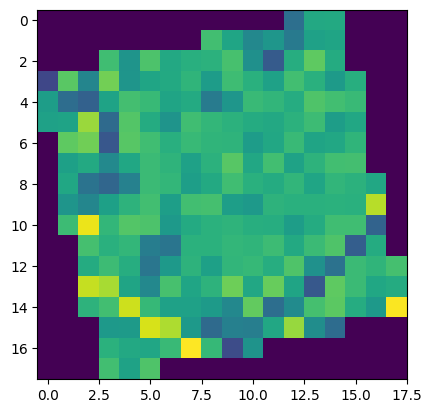

In [13]:
gray = crop_array[16, :, :]

plt.imshow(gray)

In [14]:
v, nv = _flatten_norm(gray, m)

In [16]:
v.shape

(234,)

In [17]:
nv.shape

()